In [4]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# Load the trained model
model = tf.keras.models.load_model(
    "../../models/best_vgg16_finetuned.keras"
)

# Check model architecture
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 41,070,929 (156.67 MB)

 Trainable params: 13,111,813 (50.02 MB)

 Non-trainable params: 1,735,488 (6.62 MB)

 Optimizer params: 26,223,628 (100.04 MB)

In [5]:
# Display all layers in our model

for layer in model.layers:
    print(layer.name, "-", layer.__class__.__name__)

input_layer_3 - InputLayer
vgg16 - Functional
global_average_pooling2d_1 - GlobalAveragePooling2D
dropout_2 - Dropout
dense_4 - Dense
dropout_3 - Dropout
dense_5 - Dense


In [6]:
# Find the VGG16 model inside our main model

for layer in model.layers:
    print(layer.name, layer.__class__.__name__)

    if isinstance(layer, tf.keras.Model):
        print("\nLayers inside", layer.name)

        for sublayer in layer.layers:
            if isinstance(sublayer, tf.keras.layers.Conv2D):
                print(sublayer.name)

input_layer_3 InputLayer
vgg16 Functional

Layers inside vgg16
block1_conv1
block1_conv2
block2_conv1
block2_conv2
block3_conv1
block3_conv2
block3_conv3
block4_conv1
block4_conv2
block4_conv3
block5_conv1
block5_conv2
block5_conv3
global_average_pooling2d_1 GlobalAveragePooling2D
dropout_2 Dropout
dense_4 Dense
dropout_3 Dropout
dense_5 Dense


In [8]:

# Get the VGG16 model
vgg16_model = model.get_layer("vgg16")

# Get the last convolutional layer
last_conv_layer = vgg16_model.get_layer("block5_conv3")

# Create a model to extract feature maps
feature_extractor = tf.keras.Model(
    inputs=vgg16_model.input,
    outputs=[last_conv_layer.output, vgg16_model.output]
)

# Get feature maps and VGG16 output
conv_outputs, vgg_outputs = feature_extractor(model.input)

# Pass VGG16 output through the classification layers
x = model.get_layer("global_average_pooling2d_1")(vgg_outputs)
x = model.get_layer("dropout_2")(x)
x = model.get_layer("dense_4")(x)
x = model.get_layer("dropout_3")(x)

predictions = model.get_layer("dense_5")(x)

# Create the final Grad-CAM model
grad_model = tf.keras.Model(
    inputs=model.input,
    outputs=[conv_outputs, predictions]
)

print("Grad-CAM model created successfully!")


Grad-CAM model created successfully!


In [15]:
import os

# Path to a sample product image
image_path = "../../data/products/sample.jpg"

print("Image exists:", os.path.exists(image_path))

Image exists: True


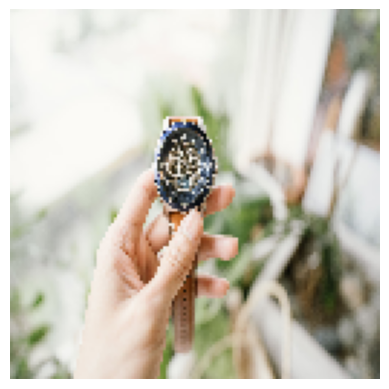

In [18]:
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.vgg16 import preprocess_input

# Load image and resize it
img = image.load_img(image_path, target_size=(128, 128))

# Convert image into array
img_array = image.img_to_array(img)

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# Display original image
plt.imshow(img)
plt.axis("off")
plt.show()

In [19]:
# Make prediction
predictions = model.predict(img_array)

# Get predicted class
predicted_class = np.argmax(predictions[0])

print("Predicted class:", predicted_class)
print("Prediction probabilities:", predictions[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 719ms/step
Predicted class: 0
Prediction probabilities: [9.7958195e-01 2.0418053e-02 7.6110165e-19 1.4359312e-22 2.9249527e-20]


In [20]:

# Use GradientTape to calculate gradients
with tf.GradientTape() as tape:

    # Get feature maps and predictions
    conv_outputs, predictions = grad_model(img_array)

    # Get the predicted class
    predicted_class = tf.argmax(predictions[0])

    # Get the score of the predicted class
    class_score = predictions[:, predicted_class]

# Calculate gradients
gradients = tape.gradient(class_score, conv_outputs)

print("Feature maps shape:", conv_outputs.shape)
print("Gradients shape:", gradients.shape)


Feature maps shape: (1, 8, 8, 512)
Gradients shape: (1, 8, 8, 512)


In [28]:
# Calculate importance weights
weights = tf.reduce_mean(gradients, axis=(0, 1, 2))

# Remove batch dimension from feature maps
feature_maps = conv_outputs[0] if len(conv_outputs.shape) == 4 else conv_outputs

# Calculate weighted sum of feature maps
heatmap = tf.reduce_sum(
    feature_maps * weights,
    axis=-1
)

# Apply ReLU
heatmap = tf.maximum(heatmap, 0)

# Normalize
heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

print("Feature maps:", feature_maps.shape)
print("Weights:", weights.shape)
print("Heatmap:", heatmap.shape)

Feature maps: (8, 512)
Weights: (512,)
Heatmap: (8,)
